# 01 · Two-stage anchor-based detector: Faster R-CNN

**Accelerator: GPU T4 x2** (COCO weights download). Inputs: competition data, `vd-utils`, output of notebook `00`.

**Protocol (same as every detector):** train on folds ≠ 0 (every 10th frame, masked, long side ≤ 1344), validate on fold 0 (every 10th frame, original images),
COCO metrics from `vd_utils.coco_evaluate` (ignore regions as `iscrowd=1`, ≤ 500 detections), FPS at batch 1, FP32, one T4.

**Model.** torchvision Faster R-CNN, ResNet-50-FPN, COCO-pretrained; the box predictor is replaced by a 9-way head (8 classes + background).
Input is resized so the long side is 1344 px (`min_size = max_size = 1344`), so 1920×1080 test frames are seen at the same scale as training frames.
Training: SGD (momentum 0.9, wd 1e-4), lr 0.01, batch 4, 8 epochs, 500-iteration warmup then cosine decay, AMP, horizontal flip.

**Runs.** Each tuned run changes **one** setting of `frcnn_base`. Version 1 trained the baseline and the anchor change; the anchor change raised `AP_small` and recall but lowered mAP, so version 2 tests the other two settings on top of the baseline, not on top of the anchors.

| run | change vs `frcnn_base` | motivation |
|---|---|---|
| `frcnn_base` | torchvision defaults: anchors 32–512, RPN 2000/1000 proposals (train/test), 512 RoIs with 25 % positives | reference |
| `frcnn_anchors` | anchor sizes 32–512 → 16–256 | the smallest default anchor (32 px) equals the median object at 1344 px (EDA §4, §9) |
| `frcnn_props` | RPN proposals 2000/1000 → 4000/2000 | up to 180 objects per frame; proposal recall of small objects is only 0.67 at IoU 0.5 (stage table below) |
| `frcnn_roi` | RoI positive fraction 0.25 → 0.5 | many small GTs per image: more positive RoIs per batch for the second-stage classifier |

Two runs train at the same time, one per GPU (version 2 needs the output of version 1 attached).

In [1]:
import os, sys, glob, gc, json, time, zipfile, subprocess, traceback
try:
    import pycocotools
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pycocotools"], check=True)
import numpy as np, pandas as pd, matplotlib.pyplot as plt, cv2, torch, torchvision

def find_utils():
    if os.path.exists("vd_utils.py"):
        return "."
    for depth in range(1, 6):
        hits = glob.glob(os.path.join("/kaggle/input", *["*"] * depth, "vd_utils.py"))
        if hits:
            return os.path.dirname(hits[0])
    raise FileNotFoundError("Add the vd-utils dataset as notebook input")

sys.path.insert(0, find_utils())
import vd_utils as U

print("torch", torch.__version__, "| torchvision", torchvision.__version__, "| GPUs", torch.cuda.device_count())

torch 2.11.0+cu130 | torchvision 0.26.0+cu130 | GPUs 2


In [2]:
# --- Configuration --------------------------------------------------------------
SEED = 42
VAL_FOLD, STEP = 0, 10
EPOCHS, BATCH, LR, WORKERS = 8, 4, 0.01, 2       # WORKERS per training process (4 CPUs, 2 processes)
KIND = "faster_rcnn"
WORK, RUNS_DIR = "/kaggle/working", "/kaggle/working/runs_tv"

ANCHORS = dict(anchor_sizes=(16, 32, 64, 128, 256))
PROPS = dict(rpn_pre_nms_top_n_train=4000, rpn_post_nms_top_n_train=4000,
             rpn_pre_nms_top_n_test=2000, rpn_post_nms_top_n_test=2000)
RUNS = {
    "frcnn_base":    {},
    "frcnn_anchors": {**ANCHORS},
    "frcnn_props":   {**PROPS},
    "frcnn_roi":     {"box_positive_fraction": 0.5},
}
RUNS_TO_TRAIN = ["frcnn_props", "frcnn_roi"]      # version 1 trained frcnn_base + frcnn_anchors
U.seed_everything(SEED)
os.makedirs(f"{WORK}/results", exist_ok=True)

In [3]:
# --- Train / validation frames and COCO ground truth --------------------------------
frames, anns = U.load_prep()
train_folds = [f for f in sorted(frames.fold.unique()) if f != VAL_FOLD]
tr = U.select_frames(frames, folds=train_folds, step=STEP)
va = U.select_frames(frames, folds=VAL_FOLD, step=STEP)
train_paths, val_paths = U.train_image_paths(tr), U.orig_image_paths(va)
gt_json, key2id = U.make_coco_gt(va, anns, f"{WORK}/gt_val.json")
val_ids = [key2id[k] for k in va.key]

objs, ign = anns[anns.iscrowd == 0], anns[anns.iscrowd == 1]
gt_by_key = {k: (np.c_[g.x, g.y, g.x + g.w, g.y + g.h], g.cls.values) for k, g in objs[objs.key.isin(key2id)].groupby("key")}
ign_by_key = {k: g[["x", "y", "w", "h"]].values for k, g in ign[ign.key.isin(key2id)].groupby("key")}
print(f"train {len(tr)} frames | val {len(va)} frames, {sum(len(v[1]) for v in gt_by_key.values())} objects")

train 2161 frames | val 573 frames, 21981 objects


## Training

In [4]:
# --- Train the selected runs, one process per GPU --------------------------------------
cfgs = [dict(name=n, kind=KIND, model_kwargs=RUNS[n], train_paths=train_paths, epochs=EPOCHS, batch=BATCH,
             lr=LR, workers=WORKERS, seed=SEED, out_dir=f"{RUNS_DIR}/{n}") for n in RUNS_TO_TRAIN]
if cfgs:
    U.train_parallel(cfgs)

Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth
Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth


100%|██████████| 160M/160M [00:00<00:00, 231MB/s]
100%|██████████| 160M/160M [00:01<00:00, 163MB/s]
/kaggle/input/datasets/vladyslavbobryk/vd-utils/vd_utils.py:673: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  sched.step()


frcnn_props {'epoch': 1, 'loss_classifier': 0.4733, 'loss_box_reg': 0.547, 'loss_objectness': 0.1044, 'loss_rpn_box_reg': 0.1319, 'skipped': 0, 'minutes': 6.2}
frcnn_roi {'epoch': 1, 'loss_classifier': 0.6355, 'loss_box_reg': 0.946, 'loss_objectness': 0.1074, 'loss_rpn_box_reg': 0.1327, 'skipped': 0, 'minutes': 6.1}
frcnn_props {'epoch': 2, 'loss_classifier': 0.3167, 'loss_box_reg': 0.4489, 'loss_objectness': 0.0595, 'loss_rpn_box_reg': 0.111, 'skipped': 0, 'minutes': 12.3}
frcnn_roi {'epoch': 2, 'loss_classifier': 0.4344, 'loss_box_reg': 0.8066, 'loss_objectness': 0.0635, 'loss_rpn_box_reg': 0.1126, 'skipped': 0, 'minutes': 12.0}
frcnn_roi {'epoch': 3, 'loss_classifier': 0.356, 'loss_box_reg': 0.7412, 'loss_objectness': 0.0487, 'loss_rpn_box_reg': 0.0984, 'skipped': 0, 'minutes': 17.9}
frcnn_props {'epoch': 3, 'loss_classifier': 0.2747, 'loss_box_reg': 0.419, 'loss_objectness': 0.0463, 'loss_rpn_box_reg': 0.0981, 'skipped': 0, 'minutes': 18.4}
frcnn_roi {'epoch': 4, 'loss_classifier':

## Validation results

`FPS` includes image decoding, resizing and post-processing (batch 1, FP32).

In [5]:
# --- Evaluate every finished run with the shared COCO evaluator -----------------------
def evaluate(name):
    gc.collect(); torch.cuda.empty_cache()
    model = U.load_detector(KIND, RUNS[name], U.find_run_file(name, "model.pt"))
    preds, dets = {}, []
    for key, img_id, p in zip(va.key, val_ids, val_paths):
        preds[key] = U.detect(model, p)
        dets += U.to_coco_dets(img_id, *preds[key])
    m = U.coco_evaluate(gt_json, dets)
    m["FPS"] = round(U.measure_fps(lambda p: U.detect(model, p), val_paths[:70], warmup=10, n=60), 1)
    info = U.find_run_file(name, "info.json")
    m["train_h"] = json.load(open(info))["train_hours"] if info else float("nan")
    return m, preds, model

results, preds_by_run = {}, {}
for name in RUNS:
    if U.find_run_file(name, "model.pt") is None:
        print(f"{name}: not trained yet")
        continue
    try:
        results[name], preds_by_run[name], _ = evaluate(name)
    except Exception:
        traceback.print_exc()     # keep the notebook alive so trained weights are saved
        continue
    with open(f"{WORK}/results/{name}.json", "w") as f:
        json.dump(results[name], f)

if results:
    res = pd.DataFrame(results).T
    display(res[["mAP", "AP50", "AP75", "AP_small", "AP_medium", "AP_large", "AR500", "FPS", "train_h"]])
    display(res[[f"AP_{c}" for c in U.CLASSES]])

,mAP,AP50,AP75,AP_small,AP_medium,AP_large,AR500,FPS,train_h
frcnn_base,0.2400,0.4710,0.2189,0.0984,0.2091,0.4323,0.4058,5.0,0.77
frcnn_anchors,0.2319,0.4656,0.2116,0.1042,0.2054,0.4371,0.4226,5.0,0.81
frcnn_props,0.2401,0.4710,0.2191,0.1000,0.2120,0.4276,0.4246,4.7,0.81
frcnn_roi,0.2381,0.4640,0.2155,0.0946,0.2056,0.4474,0.4033,5.0,0.79


,AP_person,AP_bicycle,AP_car,AP_van,AP_truck,AP_tricycle,AP_bus,AP_motor
frcnn_base,0.2092,0.0263,0.4490,0.2428,0.1883,0.1990,0.4566,0.1488
frcnn_anchors,0.2132,0.0444,0.4478,0.2396,0.1645,0.1948,0.4158,0.1375
frcnn_props,0.2152,0.0336,0.4567,0.2334,0.1754,0.1929,0.4681,0.1475
frcnn_roi,0.2052,0.0367,0.4505,0.2368,0.1904,0.2014,0.4393,0.1445


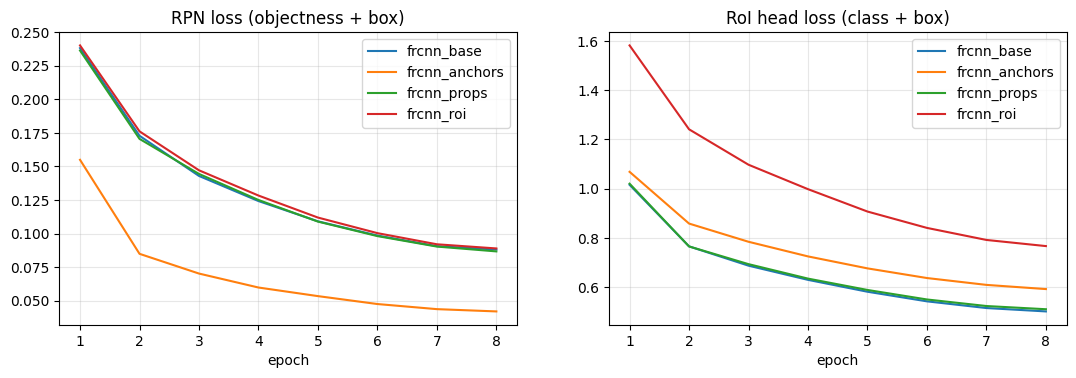

In [6]:
# --- Training loss per epoch ------------------------------------------------------------
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
for name in RUNS:
    lp = U.find_run_file(name, "log.json")
    if lp:
        log = pd.DataFrame(json.load(open(lp)))
        ax[0].plot(log.epoch, log.loss_objectness + log.loss_rpn_box_reg, label=name)
        ax[1].plot(log.epoch, log.loss_classifier + log.loss_box_reg, label=name)
ax[0].set_title("RPN loss (objectness + box)"); ax[1].set_title("RoI head loss (class + box)")
for a in ax:
    a.set_xlabel("epoch"); a.legend(); a.grid(alpha=.3)
plt.savefig(f"{WORK}/results/frcnn_losses.png", dpi=120, bbox_inches="tight"); plt.show()

## What each stage contributes

**Stage 1 – Region Proposal Network.** For every anchor on every FPN level it predicts an objectness score and a box offset, then keeps the top proposals after NMS.
It is class-agnostic and its job is **recall**: an object without a nearby proposal can never be detected.
**Stage 2 – RoI head.** RoIAlign crops a fixed 7×7 feature for each proposal; two FC layers **classify** it into 8 classes or background and **refine** the box again.
It provides precision (rejecting background proposals, choosing the class) and better localisation.

The table below measures this on the best run: proposal recall (class-agnostic, all test-time proposals) versus recall of the final detections (class-aware), at IoU 0.5 and 0.7.
The gap at IoU 0.5 shows what the RoI head loses (misclassified or suppressed objects); the change from IoU 0.5 to 0.7 shows how much the second regression tightens boxes.

In [7]:
# --- Proposal recall vs final detection recall on the best run ------------------------
def recall(pred_boxes, gt_boxes, thr, pred_cls=None, gt_cls=None):
    if len(gt_boxes) == 0:
        return np.zeros(0, bool)
    if len(pred_boxes) == 0:
        return np.zeros(len(gt_boxes), bool)
    iou = U.box_iou_np(gt_boxes, pred_boxes)
    if pred_cls is not None:
        iou = iou * (gt_cls[:, None] == pred_cls[None, :])
    return iou.max(1) >= thr

if results:
    best = max(results, key=lambda n: results[n]["mAP"])
    model = U.load_detector(KIND, RUNS[best], U.find_run_file(best, "model.pt"))
    rows = []
    for key, p in list(zip(va.key, val_paths))[::4]:            # every 4th validation frame
        g, gc_ = gt_by_key.get(key, (np.zeros((0, 4)), np.zeros(0)))
        props = U.rpn_proposals(model, p)
        b, s, c = preds_by_run[best][key]
        size = np.sqrt((g[:, 2] - g[:, 0]) * (g[:, 3] - g[:, 1]))
        for thr in (0.5, 0.7):
            rows.append(pd.DataFrame({"iou": thr, "small": size < 32,
                                      "proposals": recall(props, g, thr),
                                      "detections": recall(b, g, thr, c, gc_),
                                      "detections score>0.3": recall(b[s > 0.3], g, thr, c[s > 0.3], gc_)}))
    r = pd.concat(rows)
    stage = r.groupby(["iou", "small"])[["proposals", "detections", "detections score>0.3"]].mean()
    stage.index = stage.index.set_levels(["medium/large", "small (<32 px)"], level="small")
    print(f"{best}: {len(props)} proposals per image at test time")
    display(stage)

frcnn_props: 2000 proposals per image at test time


proposals  detections  detections score>0.3
iou small                                                      
0.5 medium/large     0.920723    0.879829              0.769945
    small (<32 px)   0.758726    0.680343              0.541947
0.7 medium/large     0.767185    0.625941              0.566984
    small (<32 px)   0.461115    0.289039              0.243723

## Failure analysis

Errors of the best run at score ≥ 0.3 (a typical operating point), on all validation frames.
False positives are typed as in TIDE: `bkg` (no object), `loc` (right class, IoU 0.1–0.5), `cls` (overlaps an object of another class), `dup` (second box on an already detected object).
Detections inside ignore regions are not counted.

In [8]:
# --- Error breakdown over the validation set -------------------------------------------
SCORE_THR = 0.3
if results:
    errs, fp_counts, fn_rows = {}, {}, []
    for key in va.key:
        g, gc_ = gt_by_key.get(key, (np.zeros((0, 4)), np.zeros(0, int)))
        e = U.frame_errors(g, gc_, ign_by_key.get(key, np.zeros((0, 4))), *preds_by_run[best][key], score_thr=SCORE_THR)
        errs[key] = e
        for t in e["fp_type"]:
            fp_counts[t] = fp_counts.get(t, 0) + 1
        size = np.sqrt((g[:, 2] - g[:, 0]) * (g[:, 3] - g[:, 1]))
        fn_rows.append(pd.DataFrame({"cls": gc_, "size": size, "missed": ~e["tp_gt"]}))
    fn = pd.concat(fn_rows)
    fn["bucket"] = pd.cut(fn["size"], [0, 16, 32, 96, np.inf], labels=["<16", "16-32", "32-96", ">96"])
    n_tp = sum(e["n_tp"] for e in errs.values())
    display(pd.Series(fp_counts, name="false positives").to_frame().T.assign(TP=n_tp))
    display(fn.groupby("bucket", observed=True).missed.agg(["mean", "size"]).rename(columns={"mean": "miss rate", "size": "objects"}).T)
    display(fn.groupby("cls").missed.mean().set_axis(U.CLASSES).rename("miss rate").to_frame().T)

,loc,bkg,cls,dup,TP
false positives,2798,4267,2388,435,15443


bucket,<16,16-32,32-96,>96
miss rate,0.504011,0.445631,0.264528,0.050249
objects,748.000000,5619.000000,13405.000000,2209.000000


,person,bicycle,car,van,truck,tricycle,bus,motor
miss rate,0.338041,0.849817,0.156045,0.561559,0.549521,0.556631,0.357798,0.472106


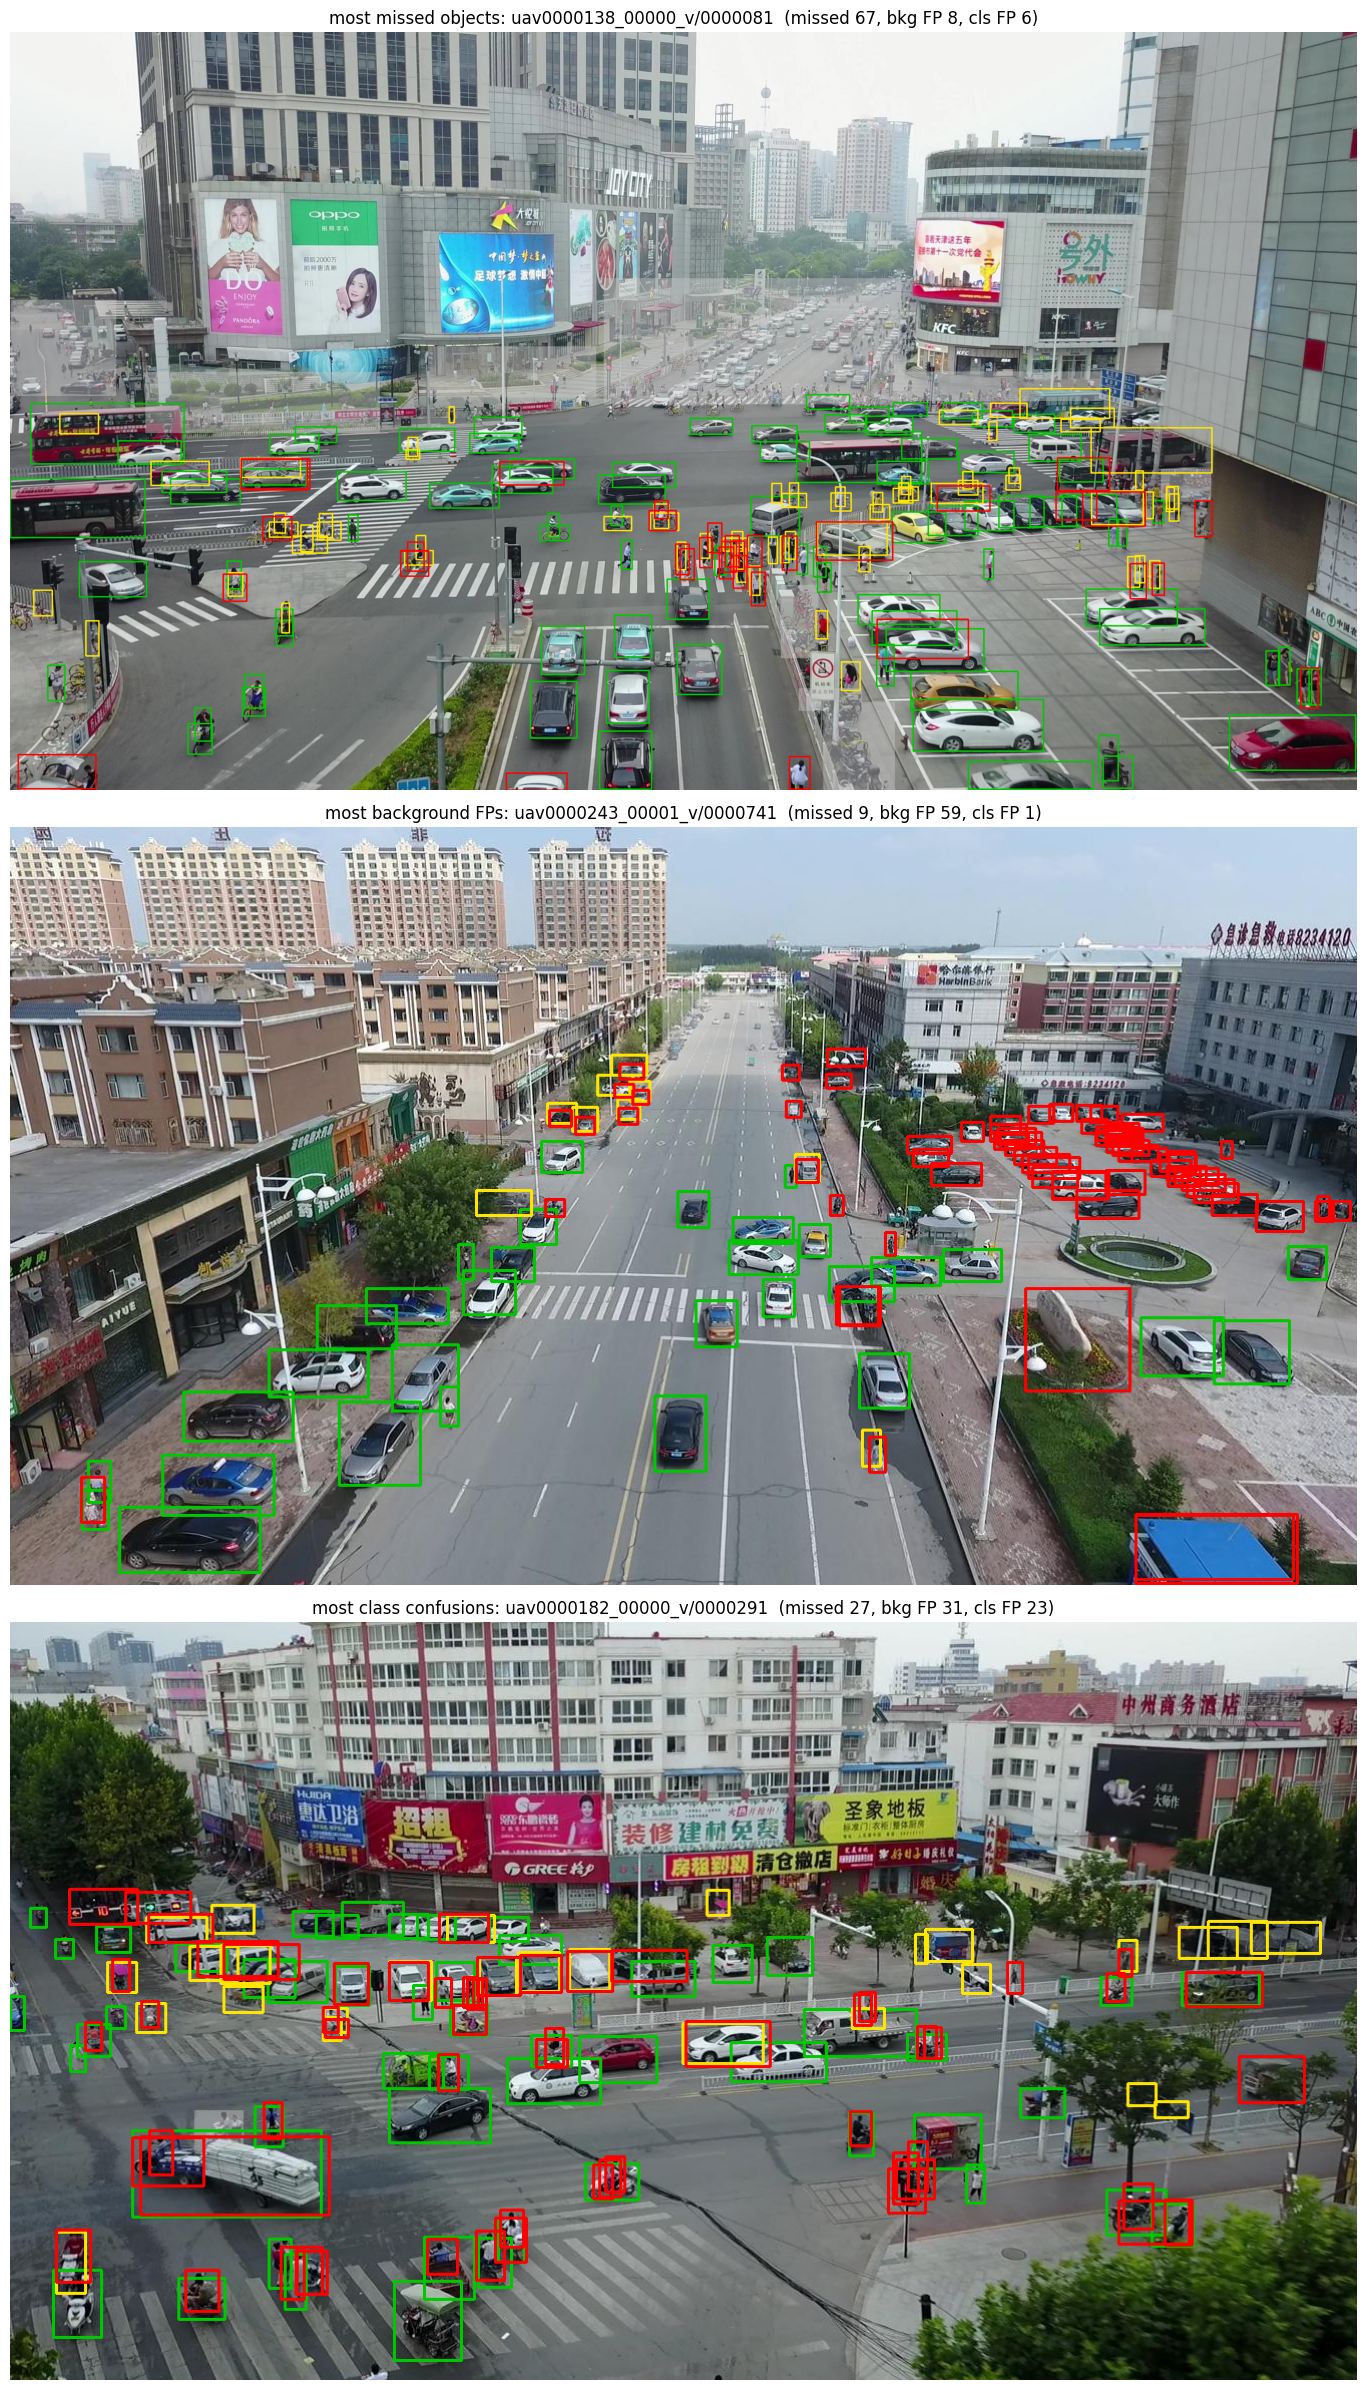

In [9]:
# --- Three representative failure frames ---------------------------------------------------
# green = detected GT, yellow = missed GT, red = false positive, gray = ignore region
if results:
    stats = pd.DataFrame({k: {"fn": e["n_fn"], "bkg": (e["fp_type"] == "bkg").sum(), "cls": (e["fp_type"] == "cls").sum()}
                          for k, e in errs.items()}).T
    picks = [("most missed objects", stats.fn.idxmax()), ("most background FPs", stats.bkg.idxmax()),
             ("most class confusions", stats["cls"].idxmax())]
    fig, ax = plt.subplots(3, 1, figsize=(14, 24))
    for a, (title, key) in zip(ax, picks):
        p = val_paths[list(va.key).index(key)]
        a.imshow(U.draw_errors(cv2.imread(p), errs[key], ign_by_key.get(key)))
        a.set_title(f"{title}: {key}  (missed {stats.loc[key, 'fn']}, bkg FP {stats.loc[key, 'bkg']}, cls FP {stats.loc[key, 'cls']})")
        a.axis("off")
    plt.tight_layout(); plt.savefig(f"{WORK}/results/frcnn_failures.png", dpi=100, bbox_inches="tight"); plt.show()

**Failure cases and plausible causes**
1. **Missed objects in a dense oblique scene** (`uav0000138_00000_v/0000081`, 67 missed). Misses (yellow) are far-away pedestrians on the crossing and partly hidden cars in the packed rows on the right; the near, unoccluded cars are found. Causes: objects of 10–20 px after resizing and heavy mutual occlusion. Proposal recall for objects < 32 px is only 0.76 even with 2 000 proposals (stage table), and NMS at IoU 0.5 can suppress a true neighbour in a tight row. Over the whole holdout, 50 % of objects < 16 px are missed vs 5 % of objects > 96 px.
2. **Background false positives that are actually unlabelled cars** (`uav0000243_00001_v/0000741`, 59 background FPs). Almost all red boxes cover real parked cars in the lot on the right; the lot is neither annotated nor marked as an ignore region. The model is right and the label is missing, so part of the "background" error is annotation noise that no detector can fix. Genuine background FPs are rare (a rock sculpture, the blue roof of a kiosk), they appear as large boxes on car-like textures.
3. **Class confusion between riders, motors, bicycles and tricycles** (`uav0000182_00000_v/0000291`, 23 class FPs). In VisDrone a rider is annotated as `person` and the vehicle under him as `motor`/`bicycle`, so two nearly identical boxes carry different classes; from above at 20–40 px a motorbike, a bicycle and a loaded tricycle look alike. This explains the class-level miss rates: `bicycle` 85 %, `tricycle` 56 %, `van` 56 % (van ↔ car), `truck` 55 % (truck ↔ van/bus).

## Test submission (best run)

In [10]:
# --- Predict the test set with the best run ---------------------------------------------
def make_submission(name):
    gc.collect(); torch.cuda.empty_cache()
    model = U.load_detector(KIND, RUNS[name], U.find_run_file(name, "model.pt"))
    test = pd.read_csv(os.path.join(U.comp_root(), "test_images.csv"))
    pred = {}
    for i, (image_id, rel) in enumerate(zip(test.image_id, test.file_name)):
        pred[image_id] = U.prediction_string(*U.detect(model, os.path.join(U.comp_root(), rel)))
        if i % 1000 == 0:
            print(f"{i}/{len(test)}")
    sub_path = f"{WORK}/submission_{name}.csv"
    sub = U.write_submission(pred, sub_path)
    with zipfile.ZipFile(sub_path[:-4] + ".zip", "w", zipfile.ZIP_DEFLATED) as z:
        z.write(sub_path, os.path.basename(sub_path))
    print(f"{name}: {len(sub)} rows, csv {os.path.getsize(sub_path) / 1e6:.0f} MB")

if results:
    try:
        make_submission(best)
    except Exception:
        traceback.print_exc()

0/3811
1000/3811
2000/3811
3000/3811
frcnn_props: 3811 rows, csv 42 MB


## Conclusions

| run | change | mAP | AP50 | AP_small | AR500 | public LB |
|---|---|---|---|---|---|---|
| `frcnn_base` | defaults | 0.240 | 0.471 | 0.098 | 0.406 | 0.2190 |
| `frcnn_anchors` | anchors 16–256 | 0.232 | 0.466 | **0.104** | 0.423 | – |
| `frcnn_props` | 4000/2000 proposals | **0.240** | **0.471** | 0.100 | **0.425** | 0.2184 |
| `frcnn_roi` | 50 % positive RoIs | 0.238 | 0.464 | 0.095 | 0.403 | – |

- **Tuning moved mAP by less than 0.01.** Smaller anchors and more proposals both raise recall (AR500 +0.02) and `AP_small`, but the extra detections are low-scoring and do not improve precision, so mAP stays flat. The bottleneck is not the number of candidates but the classification and localisation of tiny objects.
- **RPN vs RoI head.** With 2 000 proposals the RPN covers 92 % of medium/large and 76 % of small objects at IoU 0.5 (1 000 proposals: 88 % / 67 %). The RoI head keeps most of them (88 % / 68 % as class-correct detections) and its score is what turns recall into precision; at IoU 0.7 small objects drop to 29 %, so tight localisation of tiny boxes is the weakest step.
- **RoI sampling** with 50 % positives slightly hurts: fewer background RoIs make the classifier less strict on background, which is the largest error type.
- **Speed:** 5 FPS at 1344 px (batch 1, FP32), 6–7× slower than YOLOv8s at 1024 px; holdout mAP is higher (0.240 vs 0.224) but the public LB is lower (0.218–0.219 vs 0.227), a difference within the noise of a 13-clip holdout. `frcnn_props` is the tuned two-stage model used in later comparisons.